<a href="https://colab.research.google.com/github/saran-shams/Classic_CV/blob/main/Stereo_Houghtransformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1:

Left Image Dimensions:  256x256
Right Image Dimensions: 256x256
Verification Successful: Both images have identical dimensions.


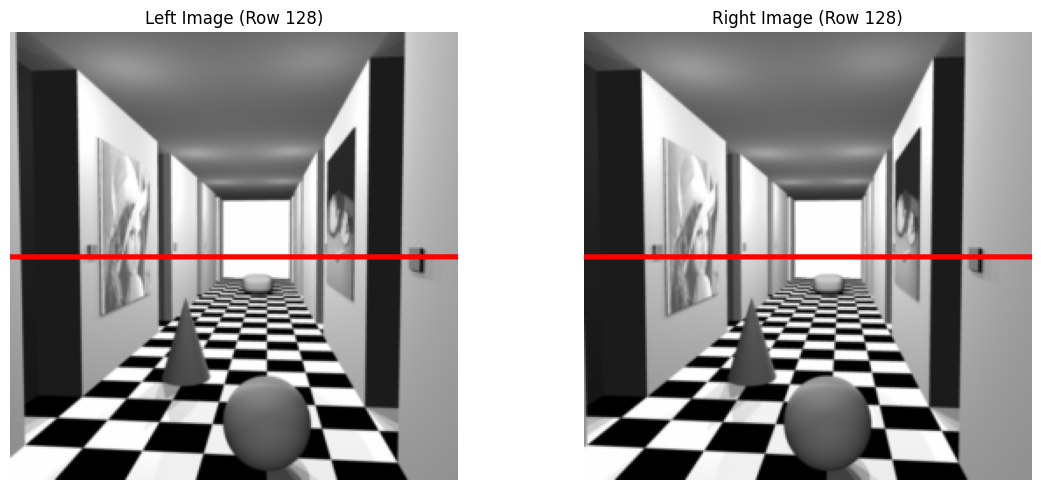

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_left = cv2.imread('Il.jpg', cv2.IMREAD_GRAYSCALE)
img_right = cv2.imread('Ir.jpg', cv2.IMREAD_GRAYSCALE)

if img_left is None or img_right is None:
    raise FileNotFoundError("Could not load one or both images. Check file paths.")

h1, w1 = img_left.shape
h2, w2 = img_right.shape

print(f"Left Image Dimensions:  {w1}x{h1}")
print(f"Right Image Dimensions: {w2}x{h2}")

if (h1, w1) == (h2, w2):
    print("Verification Successful: Both images have identical dimensions.")
else:
    raise ValueError("Image dimensions do not match!")

selected_row = h1 // 2

img_left_lines = cv2.cvtColor(img_left, cv2.COLOR_GRAY2BGR)
img_right_lines = cv2.cvtColor(img_right, cv2.COLOR_GRAY2BGR)

cv2.line(img_left_lines, (0, selected_row), (w1, selected_row), (0, 0, 255), 2)
cv2.line(img_right_lines, (0, selected_row), (w2, selected_row), (0, 0, 255), 2)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(cv2.cvtColor(img_left_lines, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Left Image (Row {selected_row})")
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(img_right_lines, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Right Image (Row {selected_row})")
axes[1].axis('off')

plt.tight_layout()
plt.show()

# Task 2:

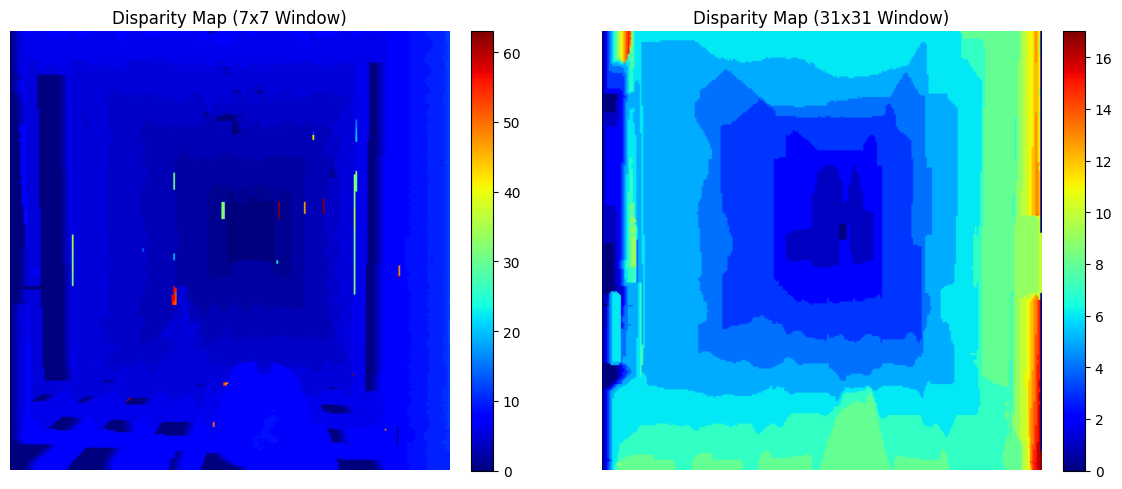

In [ ]:
def compute_ssd_disparity(img_left, img_right, window_size=7, max_disp=64):
    """
    Computes a disparity map using Sum of Squared Differences (SSD).
    """
    h, w = img_left.shape
    half_win = window_size // 2

    img_l_pad = np.pad(img_left, half_win, mode='reflect').astype(np.float32)
    img_r_pad = np.pad(img_right, half_win, mode='reflect').astype(np.float32)

    disparity_map = np.zeros((h, w), dtype=np.float32)

    for y in range(h):
        for x in range(w):
            patch_l = img_l_pad[y : y + window_size, x : x + window_size]

            best_ssd = float('inf')
            best_d = 0

            for d in range(min(max_disp, x + 1)):
                patch_r = img_r_pad[y : y + window_size, x - d : x - d + window_size]


                if np.sum((patch_l - patch_r) ** 2) < best_ssd:
                    best_ssd = np.sum((patch_l - patch_r) ** 2)
                    best_d = d

            disparity_map[y, x] = best_d

    return disparity_map

disp_7x7 = compute_ssd_disparity(img_left, img_right, window_size=7, max_disp=64)
disp_31x31 = compute_ssd_disparity(img_left, img_right, window_size=31, max_disp=64)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im0 = axes[0].imshow(disp_7x7, cmap='jet')
axes[0].set_title("Disparity Map (7x7 Window)")
axes[0].axis('off')
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(disp_31x31, cmap='jet')
axes[1].set_title("Disparity Map (31x31 Window)")
axes[1].axis('off')
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

# Task 3:

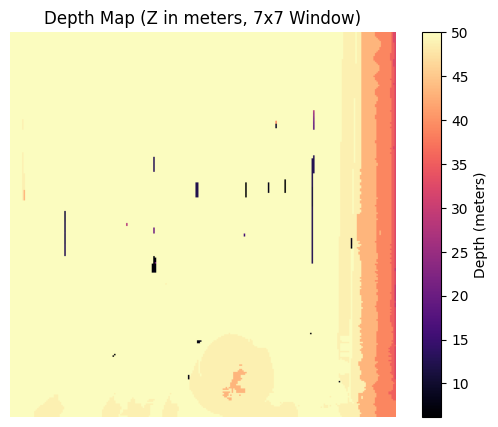

In [ ]:
B = 0.54      # meters
f = 721.5     # pixels

disparity_safe = np.where(disp_7x7 == 0, 1e-5, disp_7x7)

depth_map = (f * B) / disparity_safe

max_depth_cutoff = 50.0  # meters
depth_map_clipped = np.clip(depth_map, 0, max_depth_cutoff)

plt.figure(figsize=(7, 5))
plt.imshow(depth_map_clipped, cmap='magma')
plt.title("Depth Map (Z in meters, 7x7 Window)")
plt.colorbar(label="Depth (meters)")
plt.axis('off')
plt.show()

# Task 4:

In [ ]:
def calculate_depth(f, B, d):
    if d == 0:
        return float('inf')
    return (f * B) / d

base_f = 721.5
base_B = 0.54
base_d = 20.0

print(f"{'Variation':<30} | {'f (px)':<10} | {'B (m)':<8} | {'d (px)':<8} | {'Depth Z (m)':<10}")
print("-" * 75)

z_base = calculate_depth(base_f, base_B, base_d)
print(f"{'Base Case':<30} | {base_f:<10.1f} | {base_B:<8.2f} | {base_d:<8.1f} | {z_base:<10.2f}")

for B_val in [0.27, 1.08]:
    z = calculate_depth(base_f, B_val, base_d)
    print(f"{f'Varying Baseline (B={B_val})':<30} | {base_f:<10.1f} | {B_val:<8.2f} | {base_d:<8.1f} | {z:<10.2f}")

for f_val in [360.75, 1443.0]:
    z = calculate_depth(f_val, base_B, base_d)
    print(f"{f'Varying Focal Length (f={f_val})':<30} | {f_val:<10.1f} | {base_B:<8.2f} | {base_d:<8.1f} | {z:<10.2f}")

for d_val in [10.0, 40.0]:
    z = calculate_depth(base_f, base_B, d_val)
    print(f"{f'Varying Disparity (d={d_val})':<30} | {base_f:<10.1f} | {base_B:<8.2f} | {d_val:<8.1f} | {z:<10.2f}")

Variation                      | f (px)     | B (m)    | d (px)   | Depth Z (m)
---------------------------------------------------------------------------
Base Case                      | 721.5      | 0.54     | 20.0     | 19.48     
Varying Baseline (B=0.27)      | 721.5      | 0.27     | 20.0     | 9.74      
Varying Baseline (B=1.08)      | 721.5      | 1.08     | 20.0     | 38.96     
Varying Focal Length (f=360.75) | 360.8      | 0.54     | 20.0     | 9.74      
Varying Focal Length (f=1443.0) | 1443.0     | 0.54     | 20.0     | 38.96     
Varying Disparity (d=10.0)     | 721.5      | 0.54     | 10.0     | 38.96     
Varying Disparity (d=40.0)     | 721.5      | 0.54     | 40.0     | 9.74      
